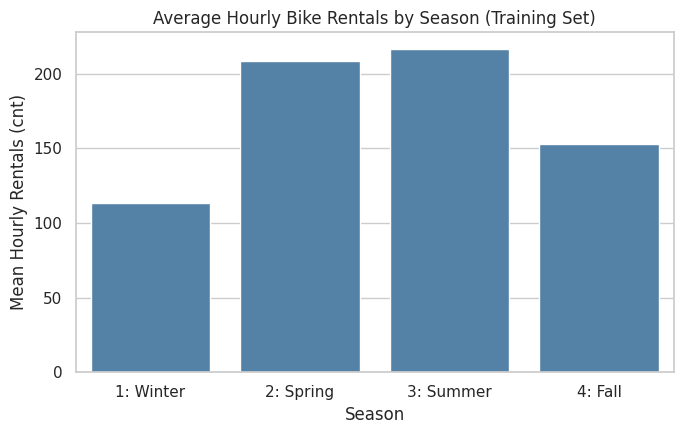

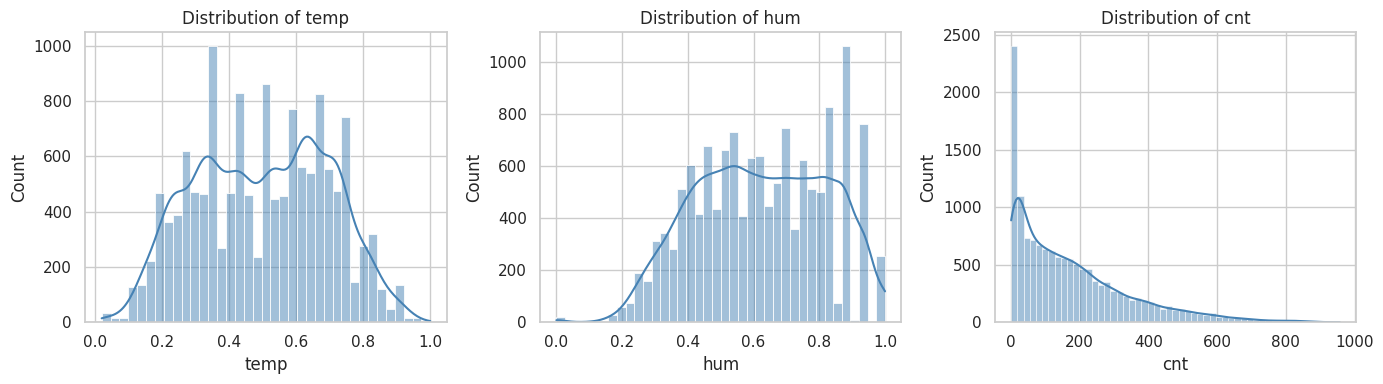

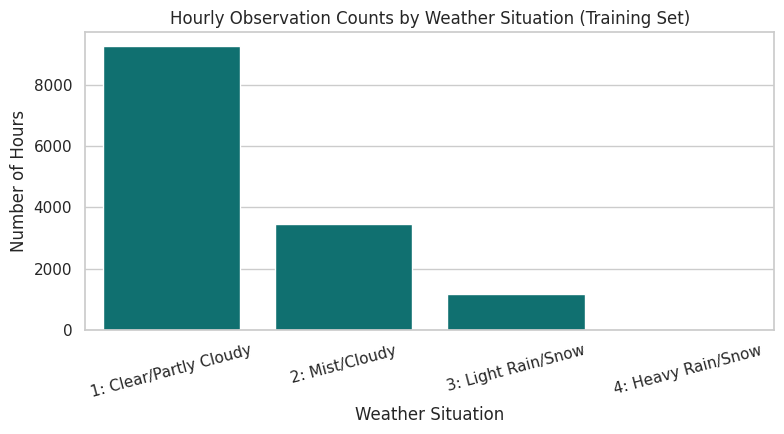

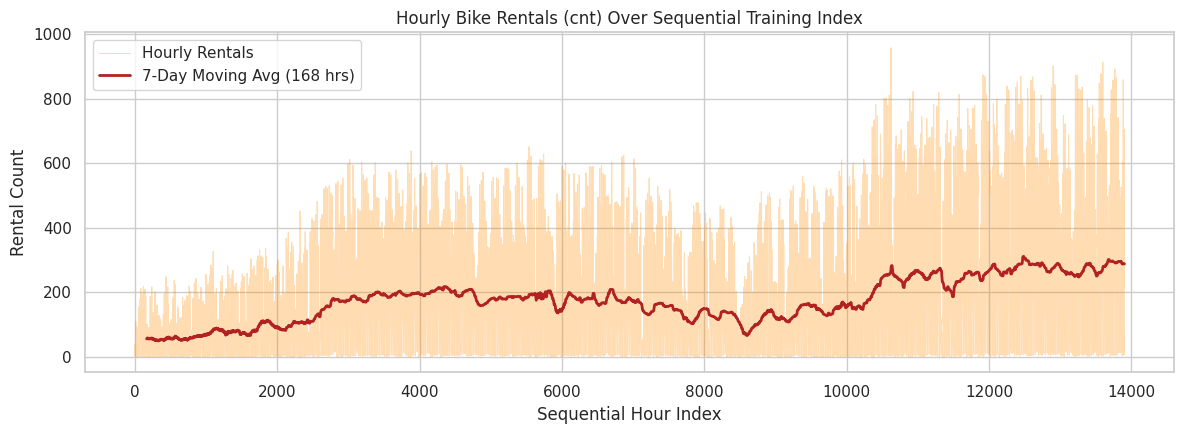

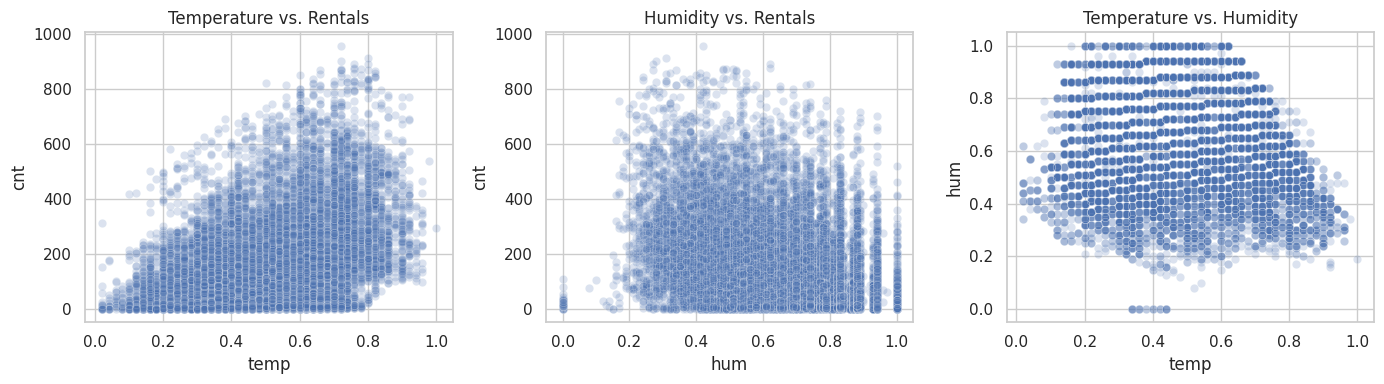

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
df = pd.read_csv("regression_train.csv")

# Reconstruct readable labels on a plotting copy only
df_plot = df.copy()
df_plot["season"] = 1 + df_plot["season_2"] + (df_plot["season_3"] * 2) + (df_plot["season_4"] * 3)
df_plot["season_label"] = df_plot["season"].map({1: "1: Winter", 2: "2: Spring", 3: "3: Summer", 4: "4: Fall"})

df_plot["weathersit"] = 1 + df_plot["weathersit_2"] + (df_plot["weathersit_3"] * 2) + (df_plot["weathersit_4"] * 3)
df_plot["weather_label"] = df_plot["weathersit"].map({
    1: "1: Clear/Partly Cloudy",
    2: "2: Mist/Cloudy",
    3: "3: Light Rain/Snow",
    4: "4: Heavy Rain/Snow"
})

# Figure 1: Mean Demand by Season (Directly supports maintenance window goal)
plt.figure(figsize=(7, 4.5))
sns.barplot(data=df_plot, x="season_label", y="cnt", estimator="mean", errorbar=None, color="steelblue")
plt.title("Average Hourly Bike Rentals by Season (Training Set)")
plt.xlabel("Season")
plt.ylabel("Mean Hourly Rentals (cnt)")
plt.tight_layout()
plt.savefig("fig1_season_demand.png", dpi=300)
plt.show()

# Figure 2: Histograms of Continuous Variables
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["temp", "hum", "cnt"]):
    sns.histplot(df_plot[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.savefig("fig2_histograms.png", dpi=300)
plt.show()

# Figure 3: Weather Severity Counts
plt.figure(figsize=(8, 4.5))
sns.countplot(data=df_plot, x="weather_label", color="teal")
plt.title("Hourly Observation Counts by Weather Situation (Training Set)")
plt.xlabel("Weather Situation")
plt.ylabel("Number of Hours")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("fig3_weather_counts.png", dpi=300)
plt.show()

# Figure 4: Sequential Trend & 7-Day Moving Average
plt.figure(figsize=(12, 4.5))
plt.plot(df_plot.index, df_plot["cnt"], color="darkorange", alpha=0.3, linewidth=0.8, label="Hourly Rentals")
plt.plot(df_plot.index, df_plot["cnt"].rolling(168).mean(), color="firebrick", linewidth=2, label="7-Day Moving Avg (168 hrs)")
plt.title("Hourly Bike Rentals (cnt) Over Sequential Training Index")
plt.xlabel("Sequential Hour Index")
plt.ylabel("Rental Count")
plt.legend()
plt.tight_layout()
plt.savefig("fig4_trend_plot.png", dpi=300)
plt.show()

# Figure 5: Bivariate Scatter Plots
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.scatterplot(data=df_plot, x="temp", y="cnt", alpha=0.2, ax=axes[0])
axes[0].set_title("Temperature vs. Rentals")

sns.scatterplot(data=df_plot, x="hum", y="cnt", alpha=0.2, ax=axes[1])
axes[1].set_title("Humidity vs. Rentals")

sns.scatterplot(data=df_plot, x="temp", y="hum", alpha=0.2, ax=axes[2])
axes[2].set_title("Temperature vs. Humidity")

plt.tight_layout()
plt.savefig("fig5_scatter_plots.png", dpi=300)
plt.show()

AI Disclosure: This script was generated with assistance from Google Gemini (2026)
for educational use in AAI-501, implementing the four core EDA visualization techniques
outlined in the Module 4 Machine Learning Lifecycle lecture.
